<a href="https://colab.research.google.com/github/GARVIT-bit/BIS/blob/main/ant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random

class AntColonyOptimization:
    def __init__(self, cities, n_ants=20, n_iterations=100, alpha=1.0, beta=2.0, decay=0.5, Q=100.0):
        self.cities = cities
        self.n_cities = len(cities)
        self.n_ants = n_ants
        self.n_iterations = n_iterations
        self.alpha = alpha  # Pheromone importance
        self.beta = beta    # Heuristic importance (1/distance)
        self.decay = decay  # Pheromone evaporation rate
        self.Q = Q          # Pheromone intensity constant

        # Distance matrix
        self.distances = self.calculate_distances(cities)
        # Pheromone matrix initialized to 1
        self.pheromones = np.ones((self.n_cities, self.n_cities))

    def calculate_distances(self, cities):
        distances = np.zeros((self.n_cities, self.n_cities))
        for i in range(self.n_cities):
            for j in range(self.n_cities):
                if i != j:
                    distances[i][j] = np.linalg.norm(cities[i] - cities[j])
                else:
                    distances[i][j] = np.inf
        return distances

    def run(self):
        best_path = None
        best_distance = float('inf')
        history = []

        for iteration in range(self.n_iterations):
            paths = []
            distances = []
            for ant in range(self.n_ants):
                path = self.generate_path()
                dist = self.calculate_path_distance(path)
                paths.append(path)
                distances.append(dist)

                if dist < best_distance:
                    best_distance = dist
                    best_path = path

            self.update_pheromones(paths, distances)
            history.append(best_distance)

            if (iteration + 1) % 10 == 0 or iteration == 0:
                print(f"Iteration {iteration+1}/{self.n_iterations} | Best Distance: {best_distance:.4f}")

        return best_path, best_distance, history

    def generate_path(self):
        path = [random.randint(0, self.n_cities - 1)]
        while len(path) < self.n_cities:
            current = path[-1]
            probabilities = self.calculate_probabilities(current, path)
            next_city = np.random.choice(range(self.n_cities), p=probabilities)
            path.append(next_city)
        return path

    def calculate_probabilities(self, current, visited):
        pheromones = self.pheromones[current]
        # Avoid division by zero by setting distance of visited to infinity in local context
        heuristics = 1.0 / self.distances[current]

        # Mask visited cities
        mask = np.ones(self.n_cities)
        mask[visited] = 0

        numerator = (pheromones ** self.alpha) * (heuristics ** self.beta) * mask
        denominator = np.sum(numerator)

        if denominator == 0:
            # If numerical precision issues occur, pick randomly among unvisited
            return mask / np.sum(mask)
        return numerator / denominator

    def calculate_path_distance(self, path):
        total_dist = 0
        for i in range(len(path)):
            total_dist += self.distances[path[i]][path[(i + 1) % len(path)]]
        return total_dist

    def update_pheromones(self, paths, distances):
        self.pheromones *= (1 - self.decay)
        for path, dist in zip(paths, distances):
            contribution = self.Q / dist
            for i in range(len(path)):
                self.pheromones[path[i]][path[(i + 1) % len(path)]] += contribution

Iteration 1/100 | Best Distance: 476.5547
Iteration 10/100 | Best Distance: 411.6236
Iteration 20/100 | Best Distance: 397.5393
Iteration 30/100 | Best Distance: 397.3317
Iteration 40/100 | Best Distance: 395.9578
Iteration 50/100 | Best Distance: 395.9578
Iteration 60/100 | Best Distance: 395.9578
Iteration 70/100 | Best Distance: 395.9578
Iteration 80/100 | Best Distance: 395.9578
Iteration 90/100 | Best Distance: 394.2482
Iteration 100/100 | Best Distance: 394.2482


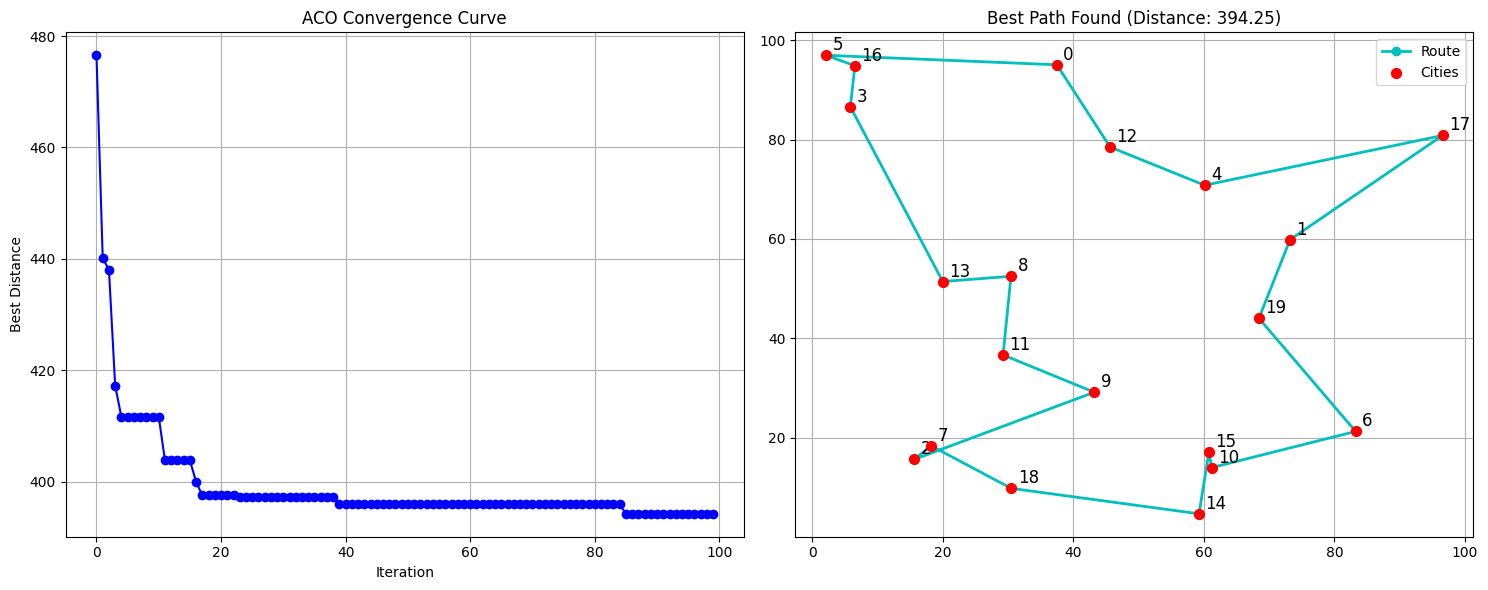

In [2]:
# Generate random cities
np.random.seed(42)
n_cities = 20
cities = np.random.rand(n_cities, 2) * 100

# Run ACO
aco = AntColonyOptimization(cities, n_ants=25, n_iterations=100, alpha=1.0, beta=2.5, decay=0.4)
best_path, best_distance, history = aco.run()

# Plot the convergence and path
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Convergence curve
ax1.plot(history, marker='o', color='b')
ax1.set_title("ACO Convergence Curve")
ax1.set_xlabel("Iteration")
ax1.set_ylabel("Best Distance")
ax1.grid(True)

# Best Path map
x = cities[best_path + [best_path[0]], 0]
y = cities[best_path + [best_path[0]], 1]
ax2.plot(x, y, 'co-', label='Route', linewidth=2)
ax2.scatter(cities[:, 0], cities[:, 1], color='red', s=50, zorder=5, label='Cities')
for idx, city in enumerate(cities):
    ax2.text(city[0] + 1, city[1] + 1, str(idx), fontsize=12)

ax2.set_title(f"Best Path Found (Distance: {best_distance:.2f})")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

Algorithm: Ant Colony Optimization (ACO) for the Traveling Salesman Problem (TSP)

Inputs:
    cities          : Set of n cities to visit
    distances       : Matrix d[i][j] representing distances between city i and city j
    num_ants        : Total number of artificial ants per iteration
    max_iterations  : Maximum number of algorithm iterations
    alpha (α)       : Influence factor of pheromone concentration
    beta (β)        : Influence factor of heuristic distance (1 / d[i][j])
    rho (ρ)         : Pheromone evaporation rate (0 < ρ <= 1)
    Q               : Pheromone constant for deposit calculation

Outputs:
    best_tour       : Shortest sequence of cities visiting every city exactly once and returning home
    best_length     : Total length of best_tour

Procedure ACO_TSP():
    1. INITIALIZATION
        For each pair of cities (i, j):
            tau[i][j] = tau_0                 // Set initial pheromone concentration to a small constant
            eta[i][j] = 1.0 / distances[i][j]  // Compute heuristic visibility (inverse distance)
        
        best_tour = None
        best_length = INFINITY

    2. MAIN ITERATION LOOP
        For iter from 1 to max_iterations:
            ant_tours = list of empty tours for each ant
            ant_lengths = array of zeros for each ant

            // Step A: Construct Solutions
            For each ant k from 1 to num_ants:
                start_city = randomly_select_city(cities)
                ant_tours[k].append(start_city)

                While len(ant_tours[k]) < n:
                    current_city = ant_tours[k].last()
                    unvisited = cities - set(ant_tours[k])

                    For each city u in unvisited:
                        weight[u] = (tau[current_city][u] ^ α) * (eta[current_city][u] ^ β)

                    sum_weights = SUM(weight[u] for all u in unvisited)

                    For each city u in unvisited:
                        probability[u] = weight[u] / sum_weights

                    next_city = select_probabilistically(unvisited, probability)
                    ant_tours[k].append(next_city)

            // Step B: Evaluate Tours
            For each ant k from 1 to num_ants:
                ant_lengths[k] = compute_total_tour_distance(ant_tours[k], distances)

                If ant_lengths[k] < best_length:
                    best_length = ant_lengths[k]
                    best_tour = ant_tours[k]

            // Step C: Update Pheromones
            // C1. Evaporation
            For each pair of cities (i, j):
                tau[i][j] = (1 - ρ) * tau[i][j]

            // C2. Deposition
            For each ant k from 1 to num_ants:
                delta_tau = Q / ant_lengths[k]
                For each edge (i, j) in ant_tours[k]:
                    tau[i][j] = tau[i][j] + delta_tau
                    tau[j][i] = tau[i][j]

    3. OUTPUT
        Return best_tour, best_length